In [1]:
import pandas as pd 
import numpy as np 
import polars as pl
from typing import List
from collections import Counter
import glob, os

import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")
from matplotlib.ticker import FuncFormatter
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans", "sans-serif"],
    "font.size": 12,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
})


import yaml
with open("../../src/configs.yml", "r") as configs:
    configs = yaml.safe_load(configs)

DATAPATH = configs["SERVER_DATA"]
ROOTPATH = configs["SERVER_WD"]

## load data
### activities around banned subreddits

In [ ]:
from src.utils.data_loader_polars import load_filtered_data

# analysis window
years = range(2005, 2020)

# load banned subreddits
sets_df = pd.read_csv("../../data-public/subreddit_sets.csv")
subreddit_sets = {
    name: set(group["subreddit"])
    for name, group in sets_df.groupby("set")
}
banned_subreddits = subreddit_sets["banned"]

# load data of banned subreddits / users
def load_post_subreddit(subm_input_fpath, comm_input_fpath, subrs=[], years=years):
    cols = ["id","author","subreddit","created_utc"]
    subm_df = load_filtered_data(years=years, data_dir=subm_input_fpath, filetype="submissions",filter_bots=False).select(cols)
    comm_df = load_filtered_data(years=years, data_dir=comm_input_fpath, filetype="comments",filter_bots=False).select(cols)
    subm_df = subm_df.with_columns(pl.lit("submission").alias("kind"))
    comm_df = comm_df.with_columns(pl.lit("comment").alias("kind"))
    post_df = pl.concat([subm_df, comm_df], how="vertical")
    if len(subrs) > 0:
        post_df = post_df.filter(pl.col("subreddit").is_in(subrs))
    return post_df

# submissions and comments by banned subreddits' users
subm_banned_user = f"{DATAPATH}/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/" 
comm_banned_user = f"{DATAPATH}/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/" 

post_banned_user = load_post_subreddit(subm_banned_user, comm_banned_user)

# submissions and comments within banned subreddits
post_banned = post_banned_user.filter(pl.col("subreddit").is_in(banned_subreddits))

Banned subreddits: 3,274
******************
Loading Submissions from /cinddata/reddit-ban-study/filtered-data-new/submissions/subm-from-user-banned-2020-subset3274-lite/...
	loading: 2005
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019
******************
Loading Comments from /cinddata/reddit-ban-study/filtered-data-new/comments/comm-from-user-banned-2020-subset3274-lite/...
	loading: 2005
	loading: 2006
	loading: 2007
	loading: 2008
	loading: 2009
	loading: 2010
	loading: 2011
	loading: 2012
	loading: 2013
	loading: 2014
	loading: 2015
	loading: 2016
	loading: 2017
	loading: 2018
	loading: 2019


### toxicity scores inside/outside banned subreddits

In [3]:
# toxicity for submissions within banned subreddits
toxicity_output_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/"
inside_scores = (
    pl.scan_parquet(f"{toxicity_output_dir}subm-comm-from-subr-banned-2020-by-subm-toxicity.parquet")
    .select(["id", "toxicity"])
    .filter(pl.col("toxicity").is_not_null())
    .unique("id")
)

inside_meta = (
    pl.scan_parquet(f"{DATAPATH}/filtered-data-new/submissions/subm-from-subr-banned-2020-subset3274/*.parquet")
    .select(["id", "author", "subreddit", "created_utc"])
    .filter(pl.col("subreddit").is_in(list(banned_subreddits)))
    .unique("id")
)
inside_subm_author = set(inside_meta.collect()["author"].unique().to_list())
# sanity check: these two dfs should have the same length
print(post_banned.filter(pl.col("kind")=="submission").shape[0])
print(inside_meta.filter(~pl.col("author").is_in(["[deleted]",""])).collect().shape[0])

inside_lf = (
    inside_scores
    .join(inside_meta.lazy(),on="id",how="inner",validate="1:1")
    .with_columns([pl.col("created_utc").cast(pl.Datetime), pl.lit("inside").alias("context")])
)

6830321
6830321


In [4]:
# toxicity for submissions outside of banned subreddits 
# (created by users who were once active in banned subreddits)

outside_score_dir = f"{DATAPATH}/output/toxicity/subset3274/detoxify-multilingual-all-subm-perweek/subm-comm-from-subm-by-user-banned-2020-subset3274-neighbors-only/"
outside_scores = (
    pl.scan_parquet(f"{outside_score_dir}/*-toxicity.parquet")
    .select(["id", "toxicity"])
    .filter(pl.col("toxicity").is_not_null())
    .unique("id")
)

outside_meta = (
    pl.scan_parquet(f"{DATAPATH}/filtered-data-new/submissions/subm-from-subm-by-user-banned-2020-subset3274-neighbors-only/*.parquet")
    .select(["id", "author", "subreddit", "created_utc",])
    .unique("id")
)
outside_subm_author = set(outside_meta.collect()["author"].unique().to_list())

outside_lf = (
    outside_scores
    .join(outside_meta.lazy(), on="id", how="inner", validate="1:1")
    .with_columns([pl.col("created_utc").cast(pl.Datetime), pl.lit("outside").alias("context")])
)

In [5]:
# combine inside/outside dataset
comparison_authors = inside_subm_author & outside_subm_author
INVALID_AUTHORS = ["", "[deleted]",]

context_lf = (
    pl.concat([inside_lf, outside_lf], how="vertical_relaxed")
    .with_columns([
        pl.col("created_utc").cast(pl.Datetime),
        pl.col("author").cast(pl.Utf8).str.strip_chars(),
        pl.col("toxicity").cast(pl.Float64),
    ])
    .filter(
        pl.col("created_utc").is_not_null()
        & pl.col("author").is_not_null()
        & pl.col("author").is_in(comparison_authors)
        & ~pl.col("author").is_in(INVALID_AUTHORS)
        & pl.col("toxicity").is_not_null()
        & pl.col("toxicity").is_finite()
    )
)

context_df = context_lf.collect()

# descriptives 
descriptives = (
    context_df
    .group_by("context")
    .agg([
        pl.len().alias("n_submissions"),
        pl.col("id").n_unique().alias("n_unique_ids"),
        pl.col("author").n_unique().alias("n_users"),
        pl.col("subreddit").n_unique().alias("n_subreddits"),
        pl.col("created_utc").min().alias("min_date"),
        pl.col("created_utc").max().alias("max_date"),
        pl.col("toxicity").mean().alias("mean_toxicity"),
    ])
    .sort("context")
)

descriptives

context,n_submissions,n_unique_ids,n_users,n_subreddits,min_date,max_date,mean_toxicity
str,u32,u32,u32,u32,datetime[μs],datetime[μs],f64
"""inside""",6306940,6306940,542708,3231,2006-02-22 07:42:02,2019-12-31 23:59:47,0.324899
"""outside""",65048689,65048689,542708,412429,2005-06-23 18:45:14,2019-12-31 23:59:59,0.186486


## configuration 

In [6]:
# prepare dataframe for user activity thresholding
user_activity_df = (
    post_banned
    .group_by("author")
    .agg([
        pl.col("id").count().alias("n_posts"),
        pl.col("created_utc").min().alias("first_post_date"),
        pl.col("created_utc").max().alias("last_post_date")
    ])
    .with_columns(((pl.col("last_post_date") - pl.col("first_post_date")).dt.total_days()+1).alias("active_days"))
)

user_activity_df

author,n_posts,first_post_date,last_post_date,active_days
str,u32,datetime[ms],datetime[ms],i64
"""Rakim_Allah777""",5,2016-11-08 05:37:29,2017-06-04 23:15:15,209
"""kdjzzang12""",11,2019-02-05 23:22:09,2019-09-20 14:41:21,227
"""PeePeeNeedGetHard""",7,2018-11-27 19:43:37,2019-06-27 04:34:53,212
"""Doommanzero""",38,2016-06-06 12:07:10,2019-11-16 16:50:41,1259
"""GuwopSoc""",9,2017-06-08 15:55:24,2018-10-23 01:34:12,502
…,…,…,…,…
"""milf_shakes""",1,2016-07-08 04:26:09,2016-07-08 04:26:09,1
"""whbsurfer""",3,2017-04-27 02:34:16,2017-09-14 23:29:08,141
"""blmaga""",16,2016-08-29 21:59:30,2017-08-29 19:52:28,365


In [7]:
from scipy.stats import t
import matplotlib.dates as mdates

TIME_WINDOW = "1mo"
# retain every user-month with at least one scored submission. 
MIN_SCORED_SUBMISSIONS = 1

# create the toxicity base dataframe with monthly truncate
toxicity_base = (
    context_df
    .select(["id", "author", "subreddit", "created_utc", "toxicity", "context",])
    .with_columns(pl.col("created_utc").dt.truncate(TIME_WINDOW).alias("period"))
)

# user-period means, separately by context
user_period_context = (
    toxicity_base
    .group_by(["period", "author", "context",])
    .agg([
        pl.col("toxicity").mean().alias("user_mean_toxicity"),
        pl.len().alias("n_scored_submissions"),
        pl.col("subreddit").n_unique().alias("n_subreddits"),
    ])
)

# user-period means across all activity
user_period_all = (
    toxicity_base
    .group_by(["period","author",])
    .agg([
        pl.col("toxicity").mean().alias("user_mean_toxicity"),
        pl.len().alias("n_scored_submissions"),
        pl.col("subreddit").n_unique().alias("n_subreddits"),
    ])
    .with_columns(pl.lit("all").alias("context"))
    .select([ 
        "period", "author", "context", 
        "user_mean_toxicity", 
        "n_scored_submissions", 
        "n_subreddits",
    ])
)

# combined user-period panel
user_period_df = pl.concat(
    [user_period_all, user_period_context,], 
    how="vertical_relaxed",).sort(["context", "author", "period",])
user_period_df

period,author,context,user_mean_toxicity,n_scored_submissions,n_subreddits
datetime[μs],str,str,f64,u32,u32
2017-02-01 00:00:00,"""-------------------c""","""all""",0.990723,1,1
2017-03-01 00:00:00,"""-------------------c""","""all""",0.291985,10,2
2017-04-01 00:00:00,"""-------------------c""","""all""",0.23722,4,1
2017-05-01 00:00:00,"""-------------------c""","""all""",0.039032,3,1
2017-06-01 00:00:00,"""-------------------c""","""all""",0.234979,13,1
…,…,…,…,…,…
2019-01-01 00:00:00,"""zzzztopportal""","""outside""",0.000527,2,1
2019-03-01 00:00:00,"""zzzztopportal""","""outside""",0.018692,1,1
2019-07-01 00:00:00,"""zzzztopportal""","""outside""",0.124024,5,3


## Aggregate across users and calculate confidence intervals

In [8]:
# average user-level toxicity over time
user_period_filtered = user_period_df.filter(pl.col("n_scored_submissions") >= MIN_SCORED_SUBMISSIONS)

user_toxicity_trends = (
    user_period_filtered
    .group_by(["period", "context"])
    .agg([
        pl.col("user_mean_toxicity").mean().alias("mean_user_toxicity"),
        pl.col("user_mean_toxicity").median().alias("median_user_toxicity"),
        pl.col("user_mean_toxicity").std(ddof=1).alias("sd_user_toxicity"),
        pl.col("user_mean_toxicity").quantile(0.25).alias("q25_user_toxicity"),
        pl.col("user_mean_toxicity").quantile(0.75).alias("q75_user_toxicity"),

        pl.len().alias("n_users"),
        pl.col("n_scored_submissions").sum().alias("n_scored_submissions"),
    ])
    .with_columns(
        (pl.col("sd_user_toxicity")/ pl.col("n_users").cast(pl.Float64).sqrt())
        .alias("se_user_toxicity")
    )
    .sort(["context","period"])
)


# Convert only the small aggregated object to pandas
trend_pd = user_toxicity_trends.to_pandas()

trend_pd["period"] = pd.to_datetime(
    trend_pd["period"]
)

trend_pd["tcrit"] = [
    t.ppf(0.975, df=n - 1)
    if n > 1 else np.nan
    for n in trend_pd["n_users"]
]

trend_pd["ci_low"] = (trend_pd["mean_user_toxicity"] - trend_pd["tcrit"] * trend_pd["se_user_toxicity"])
trend_pd["ci_high"] = (trend_pd["mean_user_toxicity"] + trend_pd["tcrit"] * trend_pd["se_user_toxicity"])

trend_pd.head()

,period,context,mean_user_toxicity,median_user_toxicity,sd_user_toxicity,q25_user_toxicity,q75_user_toxicity,n_users,n_scored_submissions,se_user_toxicity,tcrit,ci_low,ci_high
0,2005-06-01,all,0.000552,0.000552,NaN,0.000552,0.000552,1,8,NaN,NaN,NaN,NaN
1,2005-07-01,all,0.026074,0.026074,NaN,0.026074,0.026074,1,71,NaN,NaN,NaN,NaN
2,2005-08-01,all,0.058166,0.084603,0.049252,0.084603,0.088554,3,44,0.028435,4.302653,-0.064182,0.180514
3,2005-09-01,all,0.047333,0.064187,0.040939,0.064187,0.077154,3,103,0.023636,4.302653,-0.054366,0.149031
4,2005-10-01,all,0.005962,0.000446,0.012115,0.000333,0.001073,5,104,0.005418,2.776445,-0.009081,0.021005


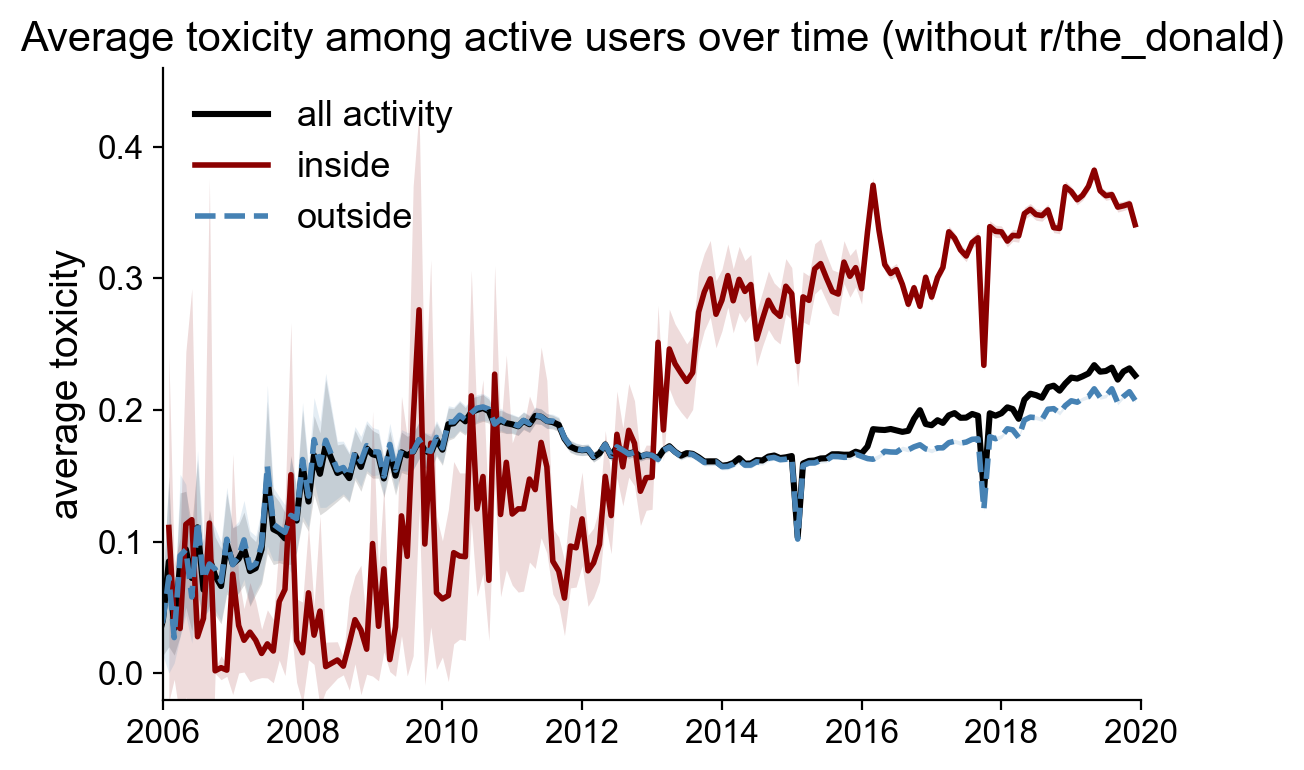

In [9]:
# plot user-level average toxicity over time
context_styles = {
    "all": {
        "label": "all activity",
        "color": "black",
        "linestyle": "-",
        "linewidth": 2.2,
    },
    "inside": {
        "label": "inside",
        "color": "darkred",
        "linestyle": "-",
        "linewidth": 2.0,
    },
    "outside": {
        "label": "outside",
        "color": "steelblue",
        "linestyle": "--",
        "linewidth": 2.0,
    },
}


def plot_user_toxicity_trends(
    trend_df,
    contexts=("all", "inside", "outside"),
    statistic="mean",
    fill_ci=True,
    year_tick_interval=2,
    ylim=None,
    figsize=(6, 4),
    savepath=None,
):

    if statistic not in {"mean", "median"}:
        raise ValueError("statistic must be 'mean' or 'median'")

    y_col = (
        "mean_user_toxicity"
        if statistic == "mean"
        else "median_user_toxicity"
    )

    fig, ax = plt.subplots(figsize=figsize)

    for context in contexts:
        this_df = trend_df.loc[trend_df["context"] == context].sort_values("period").copy()

        if this_df.empty:
            print(f"Warning: no observations for context={context!r}")
            continue

        style = context_styles[context]

        ax.plot(
            this_df["period"],
            this_df[y_col],
            label=style["label"],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=style["linewidth"],
        )

        if (
            fill_ci
            and statistic == "mean"
            and this_df["ci_low"].notna().any()
        ):
            ax.fill_between(
                this_df["period"].to_numpy(),
                this_df["ci_low"].to_numpy(dtype=float),
                this_df["ci_high"].to_numpy(dtype=float),
                color=style["color"],
                alpha=0.14,
                linewidth=0,
            )

    ax.set_xlabel("")
    ax.set_ylabel(f"average toxicity", fontsize=14)

    # ax.set_title("Average toxicity among active users over time", fontsize=15)
    ax.set_title("Average toxicity among active users over time (without r/the_donald)", fontsize=15)

    ax.xaxis.set_major_locator(mdates.YearLocator(year_tick_interval))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    ax.set_xlim(pd.Timestamp("2006-01-01"), pd.Timestamp("2020-01-01"))
    ax.set_ylim(-0.02, 0.46)

    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.legend(frameon=False, fontsize=13, loc=2)

    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()

    if savepath is not None:
        fig.savefig(
            savepath,
            dpi=300,
            bbox_inches="tight",
        )

    return fig, ax


fig, ax = plot_user_toxicity_trends(
    trend_df=trend_pd,
    contexts=("all", "inside", "outside"),
    statistic="mean",
    fill_ci=True,
    year_tick_interval=2,
    ylim=None,
    # savepath=(
    #     "../../output/260727-output-remote/"
    #     "mean-user-level-toxicity-monthly.pdf"
    # ),
)

plt.show()

In [10]:
# parameter configuration
OUTCOME = "all"   # choose "outside" or "all"
# OUTCOME = "outside"  
WINDOW_DAYS = 365
MIN_SUBMISSIONS_EACH_PERIOD = 10
INSIDE_ACTIVITY_THRESHOLD = 200
INSIDE_LIFESPAN_THRESHOLD = 30

# identify each user's first activity within banned subreddits
first_entry = (
    post_banned
    .with_columns([
        pl.col("created_utc").cast(pl.Datetime),
        pl.col("author").cast(pl.Utf8).str.strip_chars(),
    ])
    .group_by("author")
    .agg(pl.col("created_utc").min().alias("entry_date"))
    .with_columns(pl.col("entry_date").dt.year().alias("entry_year"))
)

first_entry.head()

author,entry_date,entry_year
str,datetime[μs],i32
"""bob_spinfuser""",2019-02-14 06:16:36,2019
"""Zodiak1dk""",2019-04-10 01:54:14,2019
"""JellyFshh07""",2019-09-17 21:59:39,2019
"""KTiOPO4""",2016-06-09 06:11:07,2016
"""GuesswhatImaweeb""",2019-07-18 07:09:37,2019


In [11]:
def get_user_prepost_df(
        context_df, 
        outcome=OUTCOME,
        window_days=WINDOW_DAYS,
        min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD,
        inside_activity_threshold=INSIDE_ACTIVITY_THRESHOLD,
        inside_lifespan_threshold=INSIDE_LIFESPAN_THRESHOLD,
    ):
    # prepare scored submissions
    toxicity_prepost = context_df.select(["id", "author", "created_utc", "toxicity", "context"])

    if outcome == "outside":
        toxicity_prepost = toxicity_prepost.filter(pl.col("context") == "outside")
    elif outcome == "all":
        pass
    else:
        raise ValueError("OUTCOME must be 'outside' or 'all'.")

    # label submissions as pre-entry or post-entry
    toxicity_prepost = (
        toxicity_prepost
        .join(first_entry, on="author", how="inner", validate="m:1")
        .filter(
            (pl.col("created_utc") >= pl.col("entry_date") - pl.duration(days=window_days))
            & (pl.col("created_utc") < pl.col("entry_date") + pl.duration(days=window_days))
        )
        .with_columns(
            pl.when(pl.col("created_utc") < pl.col("entry_date"))
            .then(pl.lit("pre"))
            .otherwise(pl.lit("post"))
            .alias("period")
        )
    )

    # calculate each user's pre/post mean toxicity
    user_period_toxicity = (
        toxicity_prepost
        .group_by(["author", "period"])
        .agg([
            pl.col("toxicity").mean().alias("mean_toxicity"),
            pl.col("toxicity").median().alias("median_toxicity"),
            pl.len().alias("n_scored_submissions"),
        ])
    )

    # create paired user-level dataset
    pre_toxicity = (
        user_period_toxicity
        .filter(pl.col("period") == "pre")
        .select([
            "author",
            pl.col("mean_toxicity").alias("pre_toxicity"),
            pl.col("n_scored_submissions").alias("n_pre_submissions"),
        ])
    )

    post_toxicity = (
        user_period_toxicity
        .filter(pl.col("period") == "post")
        .select([
            "author",
            pl.col("mean_toxicity").alias("post_toxicity"),
            pl.col("n_scored_submissions").alias("n_post_submissions"),
        ])
    )

    user_prepost = (
        pre_toxicity
        .join(post_toxicity, on="author", how="inner", validate="1:1")
        .join(user_activity_df, on="author", how="inner")
        .filter(
            (pl.col("n_pre_submissions") >= min_submissions_per_period)
            & (pl.col("n_post_submissions") >= min_submissions_per_period)
            & (pl.col("n_posts") >= inside_activity_threshold)
            & (pl.col("active_days") >= inside_lifespan_threshold)
        )
        .with_columns(
            (pl.col("post_toxicity") - pl.col("pre_toxicity")).alias("toxicity_change")
        )
    )

    return user_prepost

In [12]:
user_prepost_all = get_user_prepost_df(
    context_df, 
    outcome="all", 
    window_days=WINDOW_DAYS, 
    min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD, 
    inside_activity_threshold=INSIDE_ACTIVITY_THRESHOLD, 
    inside_lifespan_threshold=INSIDE_LIFESPAN_THRESHOLD)
user_prepost_outside = get_user_prepost_df(
    context_df, 
    outcome="outside", 
    window_days=WINDOW_DAYS, 
    min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD, 
    inside_activity_threshold=INSIDE_ACTIVITY_THRESHOLD, 
    inside_lifespan_threshold=INSIDE_LIFESPAN_THRESHOLD)

## to visualize for only one configuration

In [13]:
user_prepost_combined = pl.concat(
    [
        user_prepost_all.with_columns(pl.lit("all").alias("outcome")),
        user_prepost_outside.with_columns(pl.lit("outside").alias("outcome")),
    ],
    how="vertical_relaxed",
).drop_nulls("toxicity_change")
user_prepost_combined

author,pre_toxicity,n_pre_submissions,post_toxicity,n_post_submissions,n_posts,first_post_date,last_post_date,active_days,toxicity_change,outcome
str,f64,u32,f64,u32,u32,datetime[ms],datetime[ms],i64,f64,str
"""purple_mAAn""",0.16685,67,0.324457,1880,2534,2017-05-18 16:55:26,2017-11-25 19:03:12,192,0.157607,"""all"""
"""HellsWindStaff""",0.131556,59,0.208209,120,312,2016-08-09 15:59:03,2019-11-12 02:32:19,1190,0.076653,"""all"""
"""caesar315""",0.16178,49,0.238987,72,293,2016-03-03 20:17:52,2018-08-03 14:54:44,883,0.077207,"""all"""
"""Galgenfrist""",0.248016,55,0.296926,58,1960,2016-02-22 19:58:41,2019-10-08 18:26:41,1324,0.04891,"""all"""
"""Langosta_9er""",0.103216,159,0.246847,33,608,2018-02-26 06:19:03,2019-10-04 03:39:49,585,0.143631,"""all"""
…,…,…,…,…,…,…,…,…,…,…
"""porncum2""",0.860696,652,0.899728,6251,311,2019-01-29 05:13:11,2019-12-31 13:25:36,337,0.039032,"""outside"""
"""BeastPenguin""",0.073851,85,0.174906,50,1149,2016-03-17 06:13:06,2019-12-21 22:26:24,1375,0.101056,"""outside"""
"""roger_van_zant""",0.191086,43,0.132463,52,373,2015-12-12 09:48:20,2017-06-28 11:17:21,565,-0.058623,"""outside"""


In [14]:
outcome_order = ["all", "outside",]

boxplot_data = [
    (
        user_prepost_combined
        .filter(pl.col("outcome") == outcome)
        .get_column("toxicity_change")
        .to_numpy()
    )
    for outcome in outcome_order
]

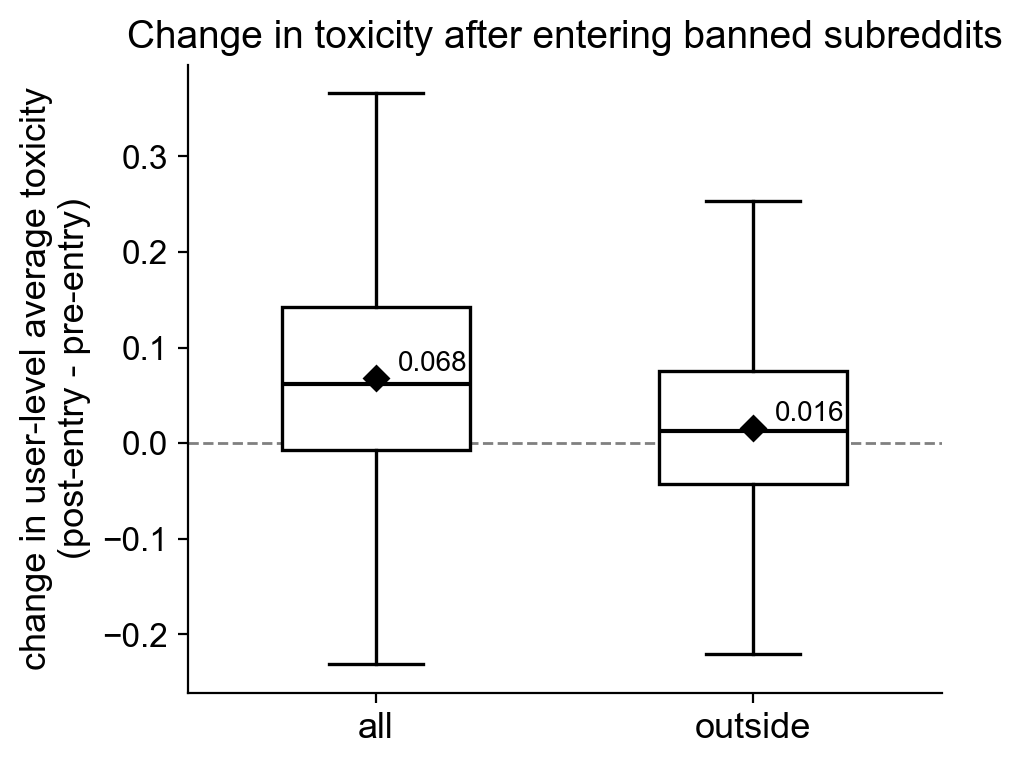

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))

bp = ax.boxplot(
    boxplot_data,
    positions=[0, 1],
    widths=0.5,
    patch_artist=True,
    showfliers=False,
    showmeans=True,
    whis=1.5,
    meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 6},
    medianprops={"color": "black", "linewidth": 1.5,},
    boxprops={"facecolor": "white", "edgecolor": "black", "linewidth": 1.2},
    whiskerprops={"color": "black", "linewidth": 1.2},
    capprops={"color": "black", "linewidth": 1.2},
)

# Reference line: no pre/post change
ax.axhline(
    0,
    color="grey",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ax.set_xticks([0, 1])
ax.set_xticklabels(outcome_order, fontsize=13)

ax.set_ylabel(
    "change in user-level average toxicity\n"
    "(post-entry - pre-entry)", fontsize=13
)
ax.set_title("Change in toxicity after entering banned subreddits", fontsize=14)

ax.spines[["top", "right"]].set_visible(False)
means = [np.mean(values) for values in boxplot_data]

for x, mean in zip([0, 1], means):
    ax.annotate(
        f"{mean:.3f}",
        xy=(x, mean+0.015),
        xytext=(8, 0),
        textcoords="offset points",
        va="center",
        fontsize=10,
    )

plt.tight_layout()
plt.show()

## to visualize several configurations at the same time

In [16]:
ACTIVITY_THRESHOLDS = [1, 10, 20, 50, 100, 200, 500, 1000]
WINDOW_DAYS = 365*5
MIN_SUBMISSIONS_EACH_PERIOD = 10
INSIDE_ACTIVITY_THRESHOLD = 200
INSIDE_LIFESPAN_THRESHOLD = 30
outcome_order = ["all", "outside"]

threshold_results = []

for threshold in ACTIVITY_THRESHOLDS:
    print("Processing inside activity threshold:", threshold)
    for outcome in outcome_order:
        result = get_user_prepost_df(
            context_df=context_df,
            outcome=outcome,
            window_days=WINDOW_DAYS,
            min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD,
            inside_activity_threshold=threshold,
            inside_lifespan_threshold=INSIDE_LIFESPAN_THRESHOLD,
        )

        result = result.with_columns([
            pl.lit(outcome).alias("outcome"),
            pl.lit(threshold).alias("inside_activity_threshold"),
        ])

        threshold_results.append(result)


user_prepost_thresholds = (
    pl.concat(
        threshold_results,
        how="vertical_relaxed",
    )
    .drop_nulls("toxicity_change")
)

user_prepost_thresholds

Processing inside activity threshold: 1


Processing inside activity threshold: 10
Processing inside activity threshold: 20
Processing inside activity threshold: 50
Processing inside activity threshold: 100
Processing inside activity threshold: 200
Processing inside activity threshold: 500
Processing inside activity threshold: 1000


author,pre_toxicity,n_pre_submissions,post_toxicity,n_post_submissions,n_posts,first_post_date,last_post_date,active_days,toxicity_change,outcome,inside_activity_threshold
str,f64,u32,f64,u32,u32,datetime[ms],datetime[ms],i64,f64,str,i32
"""oldkidgrumble""",0.263553,39,0.172943,16,781,2017-10-05 22:22:27,2019-12-18 03:05:27,804,-0.090609,"""all""",1
"""purple_mAAn""",0.16685,67,0.325505,1918,2534,2017-05-18 16:55:26,2017-11-25 19:03:12,192,0.158655,"""all""",1
"""948""",0.071003,24,0.211892,96,32,2017-07-24 14:21:18,2018-04-28 20:39:46,279,0.140889,"""all""",1
"""crawlerz2468""",0.177722,1565,0.16748,557,2,2016-02-29 19:25:20,2019-09-22 16:20:43,1301,-0.010242,"""all""",1
"""Lucylouuuu""",0.430697,23,0.721416,12,6,2018-12-24 07:12:27,2019-02-24 06:36:17,62,0.290719,"""all""",1
…,…,…,…,…,…,…,…,…,…,…,…
"""Liiivet""",0.25771,12,0.061258,33,1152,2017-02-16 21:41:40,2019-12-31 09:38:58,1048,-0.196452,"""outside""",1000
"""Teuthex""",0.168623,78,0.061885,17,1262,2016-06-17 06:06:42,2019-03-14 03:43:29,1000,-0.106737,"""outside""",1000
"""CharlieBumSlapper""",0.114488,11,0.200777,87,1369,2016-11-05 14:08:41,2018-09-19 02:21:14,683,0.08629,"""outside""",1000


In [17]:
# check sample sizes
threshold_sample_sizes = (
    user_prepost_thresholds
    .group_by(["inside_activity_threshold", "outcome"])
    .agg([
        pl.len().alias("n_users"),
        pl.col("toxicity_change").mean().alias("mean_change"),
        pl.col("toxicity_change").median().alias("median_change"),
    ])
    .sort(["inside_activity_threshold", "outcome"])
)

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(threshold_sample_sizes.filter(pl.col("outcome") == "all"))
    print(threshold_sample_sizes.filter(pl.col("outcome") == "outside"))

shape: (8, 5)
┌───────────────────────────┬─────────┬─────────┬─────────────┬───────────────┐
│ inside_activity_threshold ┆ outcome ┆ n_users ┆ mean_change ┆ median_change │
│ ---                       ┆ ---     ┆ ---     ┆ ---         ┆ ---           │
│ i32                       ┆ str     ┆ u32     ┆ f64         ┆ f64           │
╞═══════════════════════════╪═════════╪═════════╪═════════════╪═══════════════╡
│ 1                         ┆ all     ┆ 103843  ┆ 0.030798    ┆ 0.023512      │
│ 10                        ┆ all     ┆ 66832   ┆ 0.041611    ┆ 0.033881      │
│ 20                        ┆ all     ┆ 49908   ┆ 0.049004    ┆ 0.040778      │
│ 50                        ┆ all     ┆ 32002   ┆ 0.059514    ┆ 0.050315      │
│ 100                       ┆ all     ┆ 21446   ┆ 0.067745    ┆ 0.059034      │
│ 200                       ┆ all     ┆ 13657   ┆ 0.078819    ┆ 0.07028       │
│ 500                       ┆ all     ┆ 6568    ┆ 0.092241    ┆ 0.086621      │
│ 1000                    

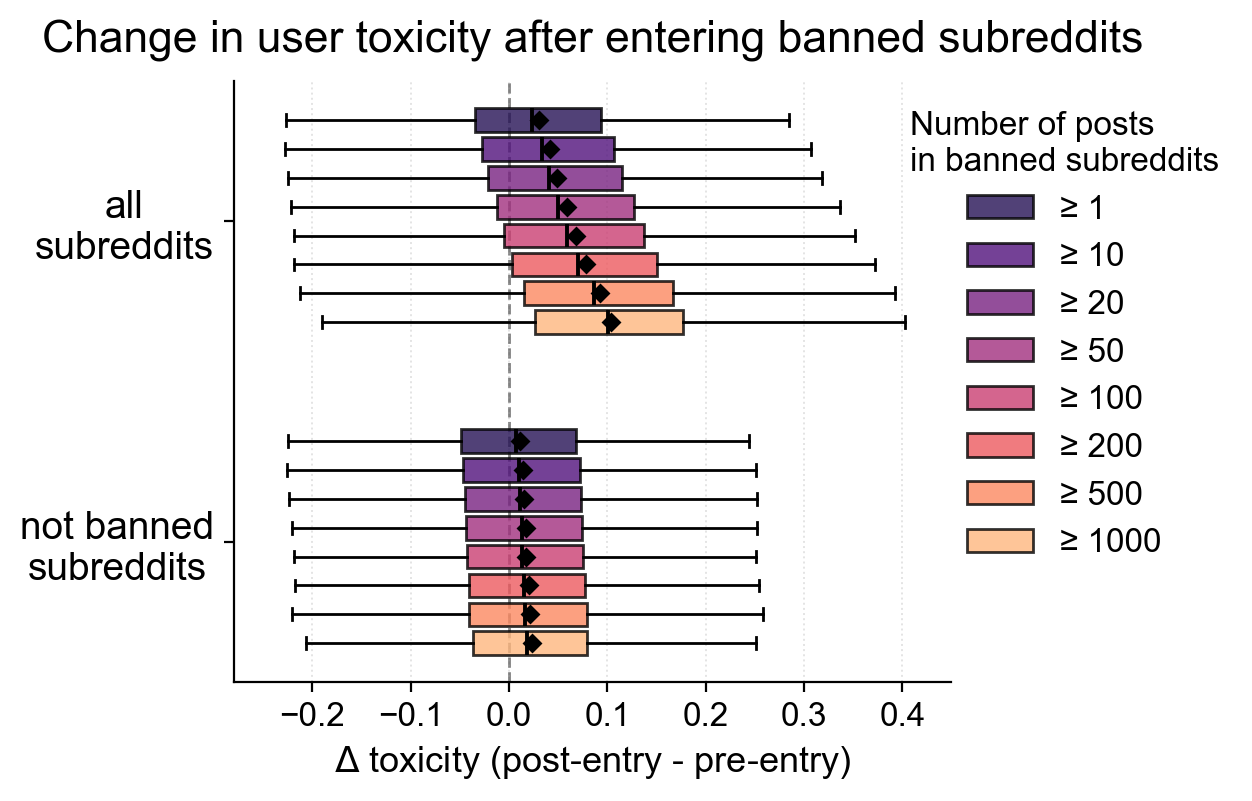

In [18]:
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory
from matplotlib.ticker import MultipleLocator

# plotting function
ACTIVITY_THRESHOLDS = sorted(ACTIVITY_THRESHOLDS)
outcome_order = ["all", "outside"]
group_centers = np.arange(len(outcome_order), dtype=float)
n_thresholds = len(ACTIVITY_THRESHOLDS)
group_height = 0.72
position_step = group_height / n_thresholds
box_height = position_step * 0.82
offsets = (np.arange(n_thresholds) - (n_thresholds - 1) / 2) * position_step
colors = plt.cm.magma(np.linspace(0.15, 0.85, n_thresholds))

fig, ax = plt.subplots(figsize=(6.3, 4.2))
legend_handles = []
sample_size_annotations = []

for threshold_idx, threshold in enumerate(ACTIVITY_THRESHOLDS):
    threshold_boxplot_data = []

    for outcome in outcome_order:
        values = (user_prepost_thresholds
            .filter(
                (pl.col("outcome") == outcome)
                & (pl.col("inside_activity_threshold") == threshold))
            .get_column("toxicity_change").drop_nulls().to_numpy())

        threshold_boxplot_data.append(values)

    # one y-position within each outcome group
    positions = group_centers + offsets[threshold_idx]

    bp = ax.boxplot(
        threshold_boxplot_data,
        positions=positions,
        widths=box_height,
        vert=False,
        manage_ticks=False,
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        whis=1.5,
        meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 4},
        medianprops={"color": "black", "linewidth": 1.4},
        boxprops={"edgecolor": "black", "linewidth": 1.0},
        whiskerprops={"color": "black", "linewidth": 1.0},
        capprops={"color": "black", "linewidth": 1.0},
    )

    for box in bp["boxes"]:
        box.set_facecolor(colors[threshold_idx])
        box.set_alpha(0.8)

    # save sample sizes and corresponding y positions
    for y_position, values in zip(positions, threshold_boxplot_data):
        sample_size_annotations.append({"y": y_position, "n": len(values)})

    legend_handles.append(
        Patch(
            facecolor=colors[threshold_idx],
            edgecolor="black",
            alpha=0.8,
            label=f"≥ {threshold}",
        )
    )

ax.axvline(0, color="grey", linestyle="--", linewidth=1, zorder=0)
ax.set_yticks(group_centers)
ax.set_yticklabels(["all\nsubreddits", "not banned\nsubreddits"], fontsize=14)
for label in ax.get_yticklabels():
    label.set_multialignment("center")
ax.invert_yaxis()
ax.set_xlabel(r"$\Delta$ toxicity"+" (post-entry - pre-entry)", fontsize=13)
ax.set_title("Change in user toxicity after entering banned subreddits", fontsize=16, y=1.02)

ax.legend(
    handles=legend_handles,
    title="Number of posts \nin banned subreddits",
    frameon=False,
    bbox_to_anchor=(0.9, 1),
    loc="upper left",
)

ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_locator(MultipleLocator(0.1))
ax.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.35)

# x_min, x_max = ax.get_xlim()
# x_span = x_max - x_min
# sample_size_x = x_max + 0.07 * x_span
# ax.set_xlim(x_min, x_max + 0.24 * x_span)
ax.set_xlim(-0.28, 0.45)

# for annotation in sample_size_annotations:
#     ax.text(
#         sample_size_x,
#         annotation["y"],
#         f"{annotation['n']:,}",
#         ha="center",
#         va="center",
#         fontsize=10,
#         zorder=5,
#         bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1.0},
#     )

# use x in data coordinates and y in axes coordinates
# header_transform = blended_transform_factory(ax.transData, ax.transAxes)

# ax.text(
#     sample_size_x,
#     1.02,
#     "sample size",
#     transform=header_transform,
#     ha="center",
#     va="top",
#     fontsize=12,
#     fontweight="bold",
# )

plt.tight_layout()
plt.savefig("../../output/mainbody/toxicity_change_banned_users_varying_activity_within.png", dpi=300, bbox_inches="tight")
plt.savefig("../../output/mainbody/toxicity_change_banned_users_varying_activity_within.pdf", dpi=300, bbox_inches="tight")

In [19]:
# === ADD: bootstrap configuration and function ===

N_BOOTSTRAPS = 5_000
BOOTSTRAP_SEED = 42

rng = np.random.default_rng(BOOTSTRAP_SEED)


def bootstrap_mean_ci(values, n_bootstraps=N_BOOTSTRAPS):
    """
    Calculate a percentile-bootstrap 95% confidence interval
    for the mean by resampling users with replacement.
    """
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)
    bootstrap_means = np.empty(n_bootstraps)

    for bootstrap_idx in range(n_bootstraps):
        bootstrap_sample = rng.choice(
            values,
            size=n,
            replace=True,
        )
        bootstrap_means[bootstrap_idx] = bootstrap_sample.mean()

    ci_low, ci_high = np.quantile(
        bootstrap_means,
        [0.025, 0.975],
    )

    return ci_low, ci_high

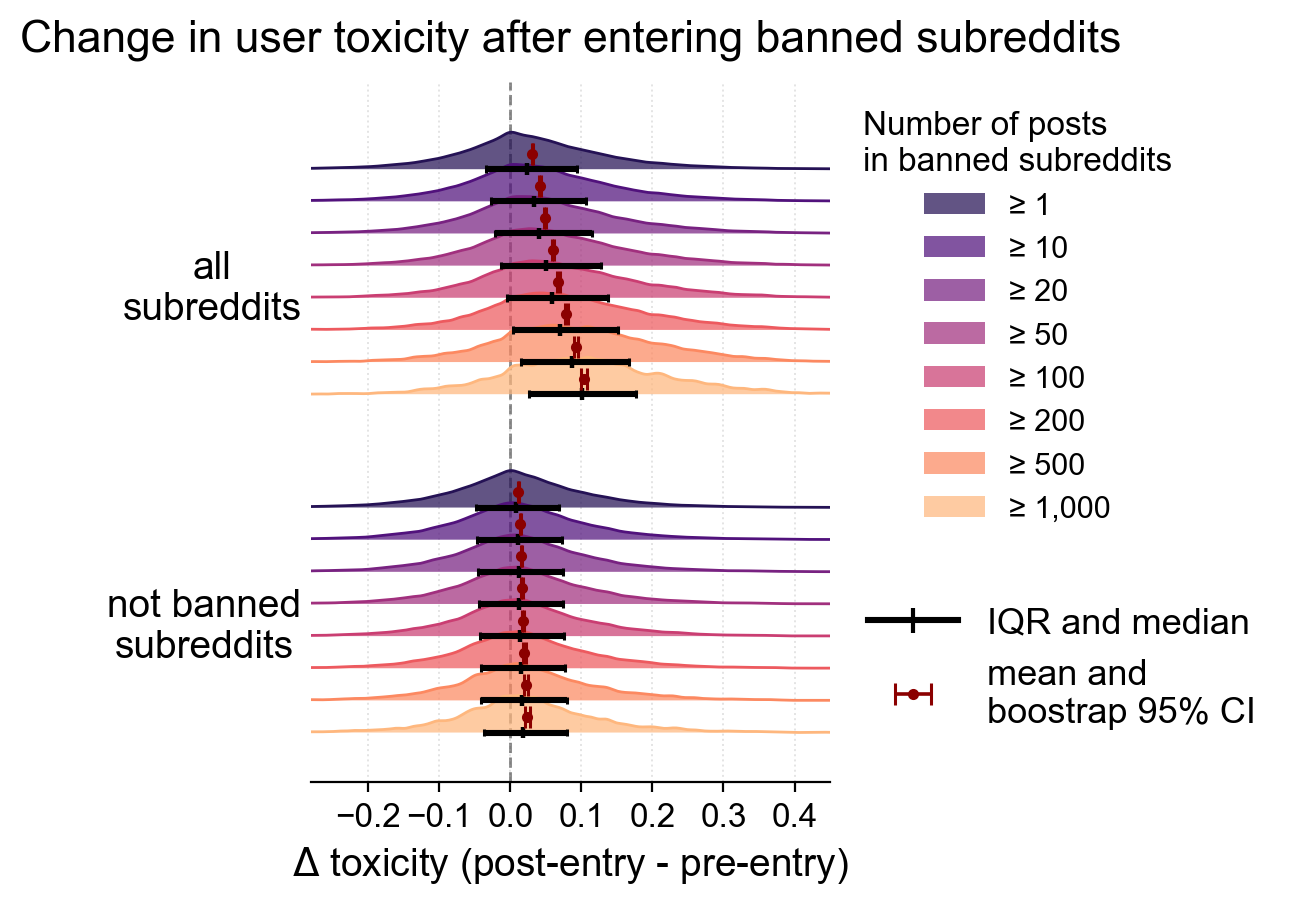

In [20]:
from scipy.ndimage import gaussian_filter1d
from scipy.stats import t
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

# configuration
ACTIVITY_THRESHOLDS = sorted(ACTIVITY_THRESHOLDS)
outcome_order = ["all", "outside"]
group_centers = np.arange(len(outcome_order), dtype=float)
n_thresholds = len(ACTIVITY_THRESHOLDS)
group_height = 0.76
position_step = group_height / n_thresholds
offsets = (np.arange(n_thresholds) - (n_thresholds - 1) / 2) * position_step
colors = plt.cm.magma(np.linspace(0.15, 0.85, n_thresholds))

# estimate each density using the complete possible range of toxicity changes
density_min, density_max = -1, 1

# display a narrower range in the final figure.
display_x_min, display_x_max = -0.28, 0.45

N_BINS = 800
SMOOTHING_SIGMA = 3
RIDGE_HEIGHT = position_step * 1.15
bin_edges = np.linspace(density_min, density_max, N_BINS + 1)
x_grid = (bin_edges[:-1] + bin_edges[1:]) / 2


# plotting function
fig, ax = plt.subplots(figsize=(6.2, 4.7))

threshold_legend_handles = []
for threshold_idx, threshold in enumerate(ACTIVITY_THRESHOLDS):

    positions = group_centers + offsets[threshold_idx]
    color = colors[threshold_idx]

    for outcome_idx, outcome in enumerate(outcome_order):

        values = (
            user_prepost_thresholds
            .filter(
                (pl.col("outcome") == outcome)
                & (pl.col("inside_activity_threshold") == threshold)
            )
            .get_column("toxicity_change").drop_nulls().to_numpy()
        )

        if len(values) == 0:
            continue

        y_position = positions[outcome_idx]

        # smoothed density using the complete distribution
        density, _ = np.histogram(values, bins=bin_edges, density=True)
        density = gaussian_filter1d(density.astype(float), sigma=SMOOTHING_SIGMA)

        # normalize ridge heights for readability.
        # ridge height therefore does not represent sample size.
        if density.max() > 0:
            density = density / density.max()

        ridge_top = (y_position - RIDGE_HEIGHT * density)

        ax.fill_between(
            x_grid, y_position,
            ridge_top,
            color=color,
            alpha=0.72,
            linewidth=0,
            zorder=2,
        )

        ax.plot(
            x_grid, ridge_top,
            color=color,
            linewidth=1.0,
            zorder=3,
        )

        # distribution summaries
        n = len(values)
        mean = np.mean(values)
        q1, median, q3 = np.quantile(values, [0.25, 0.50, 0.75])

        iqr_y = y_position
        mean_ci_y = (y_position - RIDGE_HEIGHT * 0.42)

        # IQR
        ax.hlines(
            y=iqr_y,
            xmin=q1,
            xmax=q3,
            color="black",
            linewidth=2.2,
            zorder=6,
        )

        # IQR end caps
        iqr_cap_height = position_step * 0.12

        ax.vlines(
            [q1, q3],
            ymin=iqr_y - iqr_cap_height,
            ymax=iqr_y + iqr_cap_height,
            color="black",
            linewidth=1.1,
            zorder=6,
        )

        # median
        ax.vlines(
            median,
            ymin=iqr_y - position_step * 0.18,
            ymax=iqr_y + position_step * 0.18,
            color="black",
            linewidth=1.6,
            zorder=7,
        )

        # mean and pointwise 95% CI
        if n > 1:

            # if calculating using classical one-sample, Student-\(t\) confidence interval
            # se = (np.std(values, ddof=1) / np.sqrt(n))
            # t_critical = t.ppf(0.975, df=n - 1)
            # ci_low = mean - t_critical * se
            # ci_high = mean + t_critical * se
            
            # if bootstrapping
            ci_low, ci_high = bootstrap_mean_ci(
                values,
                n_bootstraps=N_BOOTSTRAPS,
            )

            ci_cap_height = position_step * 0.14

            ax.errorbar(
                x=mean, y=mean_ci_y,
                xerr=np.array([
                    [mean - ci_low],
                    [ci_high - mean],
                ]),
                fmt=".",
                color="darkred",          # mean marker
                ecolor="darkred",       # CI line and end caps
                markersize=6,
                elinewidth=1.3,
                capsize=4,
                capthick=1.1,
                zorder=9,
            )

    threshold_legend_handles.append(
        Patch(facecolor=color, edgecolor="none", alpha=0.72, label=f"≥ {threshold:,}")
    )

# reference line and axes
ax.axvline(0, color="grey", linestyle="--", linewidth=1, zorder=1)
ax.set_yticks(group_centers)
ax.set_yticklabels(["all\nsubreddits", "not banned\nsubreddits"], fontsize=14)

for label in ax.get_yticklabels():
    label.set_multialignment("center")

ax.invert_yaxis()
ax.set_xlabel(r"$\Delta$ toxicity (post-entry - pre-entry)", fontsize=14)
ax.set_title("Change in user toxicity after entering banned subreddits", fontsize=16, y=1.02)

ax.set_xlim(display_x_min, display_x_max)
ax.xaxis.set_major_locator(MultipleLocator(0.1))
ax.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.35, zorder=0)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)

# legends
threshold_legend = ax.legend(
    handles=threshold_legend_handles,
    title="Number of posts\nin banned subreddits",
    frameon=False,
    bbox_to_anchor=(1.01, 1),
    loc="upper left",
    fontsize=11,
    title_fontsize=12,
)

ax.add_artist(threshold_legend)

iqr_handle = Line2D(
    [0], [0],
    color="black",
    linewidth=2.2,
    marker="|",
    markersize=9,
    markeredgewidth=1.5,
    label="IQR and median",
)

mean_ci_handle = ax.errorbar(
    [np.nan],
    [np.nan],
    xerr=[0.1],
    fmt=".",
    color="darkred",       # mean marker
    ecolor="darkred",    # CI and caps
    markersize=6,
    elinewidth=1.3,
    capsize=4,
    capthick=1.1,
    label="mean and \nboostrap 95% CI",
)

ax.legend(
    handles=[iqr_handle, mean_ci_handle],
    frameon=False,
    bbox_to_anchor=(1.01, 0.03),
    loc="lower left",
    fontsize=13,
    handlelength=2.5,
)


# leave enough space for the top and bottom ridges
ax.set_ylim(
    group_centers[-1] + group_height / 2 + 0.10,
    group_centers[0] - group_height / 2 - RIDGE_HEIGHT - 0.10,
)

plt.tight_layout()
# plt.savefig("../../output/mainbody/toxicity_change_banned_users_varying_activity_ridge.png", dpi=300, bbox_inches="tight")
# plt.savefig("../../output/mainbody/toxicity_change_banned_users_varying_activity_ridge.pdf", dpi=300, bbox_inches="tight")
plt.show()

## robustness test using different WINDOW_DAYS

In [21]:
# ============================================================
# Construct datasets across alternative pre/post window lengths
# ============================================================

WINDOW_SPECS = [
    (90, "3 months"),
    (180, "6 months"),
    (365, "1 year"),
    (365 * 2, "2 years"),
    (365 * 3, "3 years"),
    (365 * 5, "5 years"),
]

ACTIVITY_THRESHOLDS = sorted([1, 10, 20, 50, 100, 200, 500, 1000])

MIN_SUBMISSIONS_EACH_PERIOD = 10
INSIDE_LIFESPAN_THRESHOLD = 30

outcome_order = ["all", "outside"]

window_results = []

for window_days, window_label in WINDOW_SPECS:

    print(f"Processing window: {window_label} ({window_days} days)")

    for outcome in outcome_order:

        # Calculate the user-level pre/post measures only once for each
        # window × outcome combination. The minimum activity threshold
        # is applied here; higher thresholds are applied below.
        base_result = get_user_prepost_df(
            context_df=context_df,
            outcome=outcome,
            window_days=window_days,
            min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD,
            inside_activity_threshold=min(ACTIVITY_THRESHOLDS),
            inside_lifespan_threshold=INSIDE_LIFESPAN_THRESHOLD,
        )

        for threshold in ACTIVITY_THRESHOLDS:

            result = (
                base_result
                .filter(pl.col("n_posts") >= threshold)
                .with_columns([
                    pl.lit(outcome).alias("outcome"),
                    pl.lit(threshold).alias(
                        "inside_activity_threshold"
                    ),
                    pl.lit(window_days).alias("window_days"),
                    pl.lit(window_label).alias("window_label"),
                ])
            )

            window_results.append(result)


user_prepost_window_robustness = (
    pl.concat(
        window_results,
        how="vertical_relaxed",
    )
    .drop_nulls("toxicity_change")
)

user_prepost_window_robustness

Processing window: 3 months (90 days)


Processing window: 6 months (180 days)
Processing window: 1 year (365 days)
Processing window: 2 years (730 days)
Processing window: 3 years (1095 days)
Processing window: 5 years (1825 days)


author,pre_toxicity,n_pre_submissions,post_toxicity,n_post_submissions,n_posts,first_post_date,last_post_date,active_days,toxicity_change,outcome,inside_activity_threshold,window_days,window_label
str,f64,u32,f64,u32,u32,datetime[ms],datetime[ms],i64,f64,str,i32,i32,str
"""purple_mAAn""",0.403456,10,0.289284,912,2534,2017-05-18 16:55:26,2017-11-25 19:03:12,192,-0.114171,"""all""",1,90,"""3 months"""
"""crawlerz2468""",0.193377,90,0.130969,66,2,2016-02-29 19:25:20,2019-09-22 16:20:43,1301,-0.062408,"""all""",1,90,"""3 months"""
"""caxtonclose""",0.007984,14,0.160181,2865,67,2017-10-25 00:13:16,2018-05-28 22:22:01,216,0.152197,"""all""",1,90,"""3 months"""
"""HellsWindStaff""",0.125873,13,0.204333,28,312,2016-08-09 15:59:03,2019-11-12 02:32:19,1190,0.07846,"""all""",1,90,"""3 months"""
"""IPostBabes""",0.108454,734,0.115159,394,5,2015-03-27 04:43:15,2015-12-01 19:41:15,250,0.006705,"""all""",1,90,"""3 months"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Liiivet""",0.25771,12,0.061258,33,1152,2017-02-16 21:41:40,2019-12-31 09:38:58,1048,-0.196452,"""outside""",1000,1825,"""5 years"""
"""Teuthex""",0.168623,78,0.061885,17,1262,2016-06-17 06:06:42,2019-03-14 03:43:29,1000,-0.106737,"""outside""",1000,1825,"""5 years"""
"""CharlieBumSlapper""",0.114488,11,0.200777,87,1369,2016-11-05 14:08:41,2018-09-19 02:21:14,683,0.08629,"""outside""",1000,1825,"""5 years"""


In [22]:
window_sample_sizes = (
    user_prepost_window_robustness
    .group_by([
        "window_days",
        "window_label",
        "inside_activity_threshold",
        "outcome",
    ])
    .agg([
        pl.len().alias("n_users"),
        pl.col("toxicity_change").mean().alias("mean_change"),
        pl.col("toxicity_change").median().alias("median_change"),
    ])
    .sort([
        "window_days",
        "inside_activity_threshold",
        "outcome",
    ])
)

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(window_sample_sizes)

shape: (96, 7)
┌─────────────┬──────────────┬───────────────────┬─────────┬─────────┬─────────────┬───────────────┐
│ window_days ┆ window_label ┆ inside_activity_t ┆ outcome ┆ n_users ┆ mean_change ┆ median_change │
│ ---         ┆ ---          ┆ hreshold          ┆ ---     ┆ ---     ┆ ---         ┆ ---           │
│ i32         ┆ str          ┆ ---               ┆ str     ┆ u32     ┆ f64         ┆ f64           │
│             ┆              ┆ i32               ┆         ┆         ┆             ┆               │
╞═════════════╪══════════════╪═══════════════════╪═════════╪═════════╪═════════════╪═══════════════╡
│ 90          ┆ 3 months     ┆ 1                 ┆ all     ┆ 47562   ┆ 0.017886    ┆ 0.013273      │
│ 90          ┆ 3 months     ┆ 1                 ┆ outside ┆ 44632   ┆ 0.007434    ┆ 0.005264      │
│ 90          ┆ 3 months     ┆ 10                ┆ all     ┆ 29208   ┆ 0.023148    ┆ 0.019176      │
│ 90          ┆ 3 months     ┆ 10                ┆ outside ┆ 27048   ┆ 0.008

processing for: 0
processing for: 1
processing for: 2
processing for: 3
processing for: 4
processing for: 5


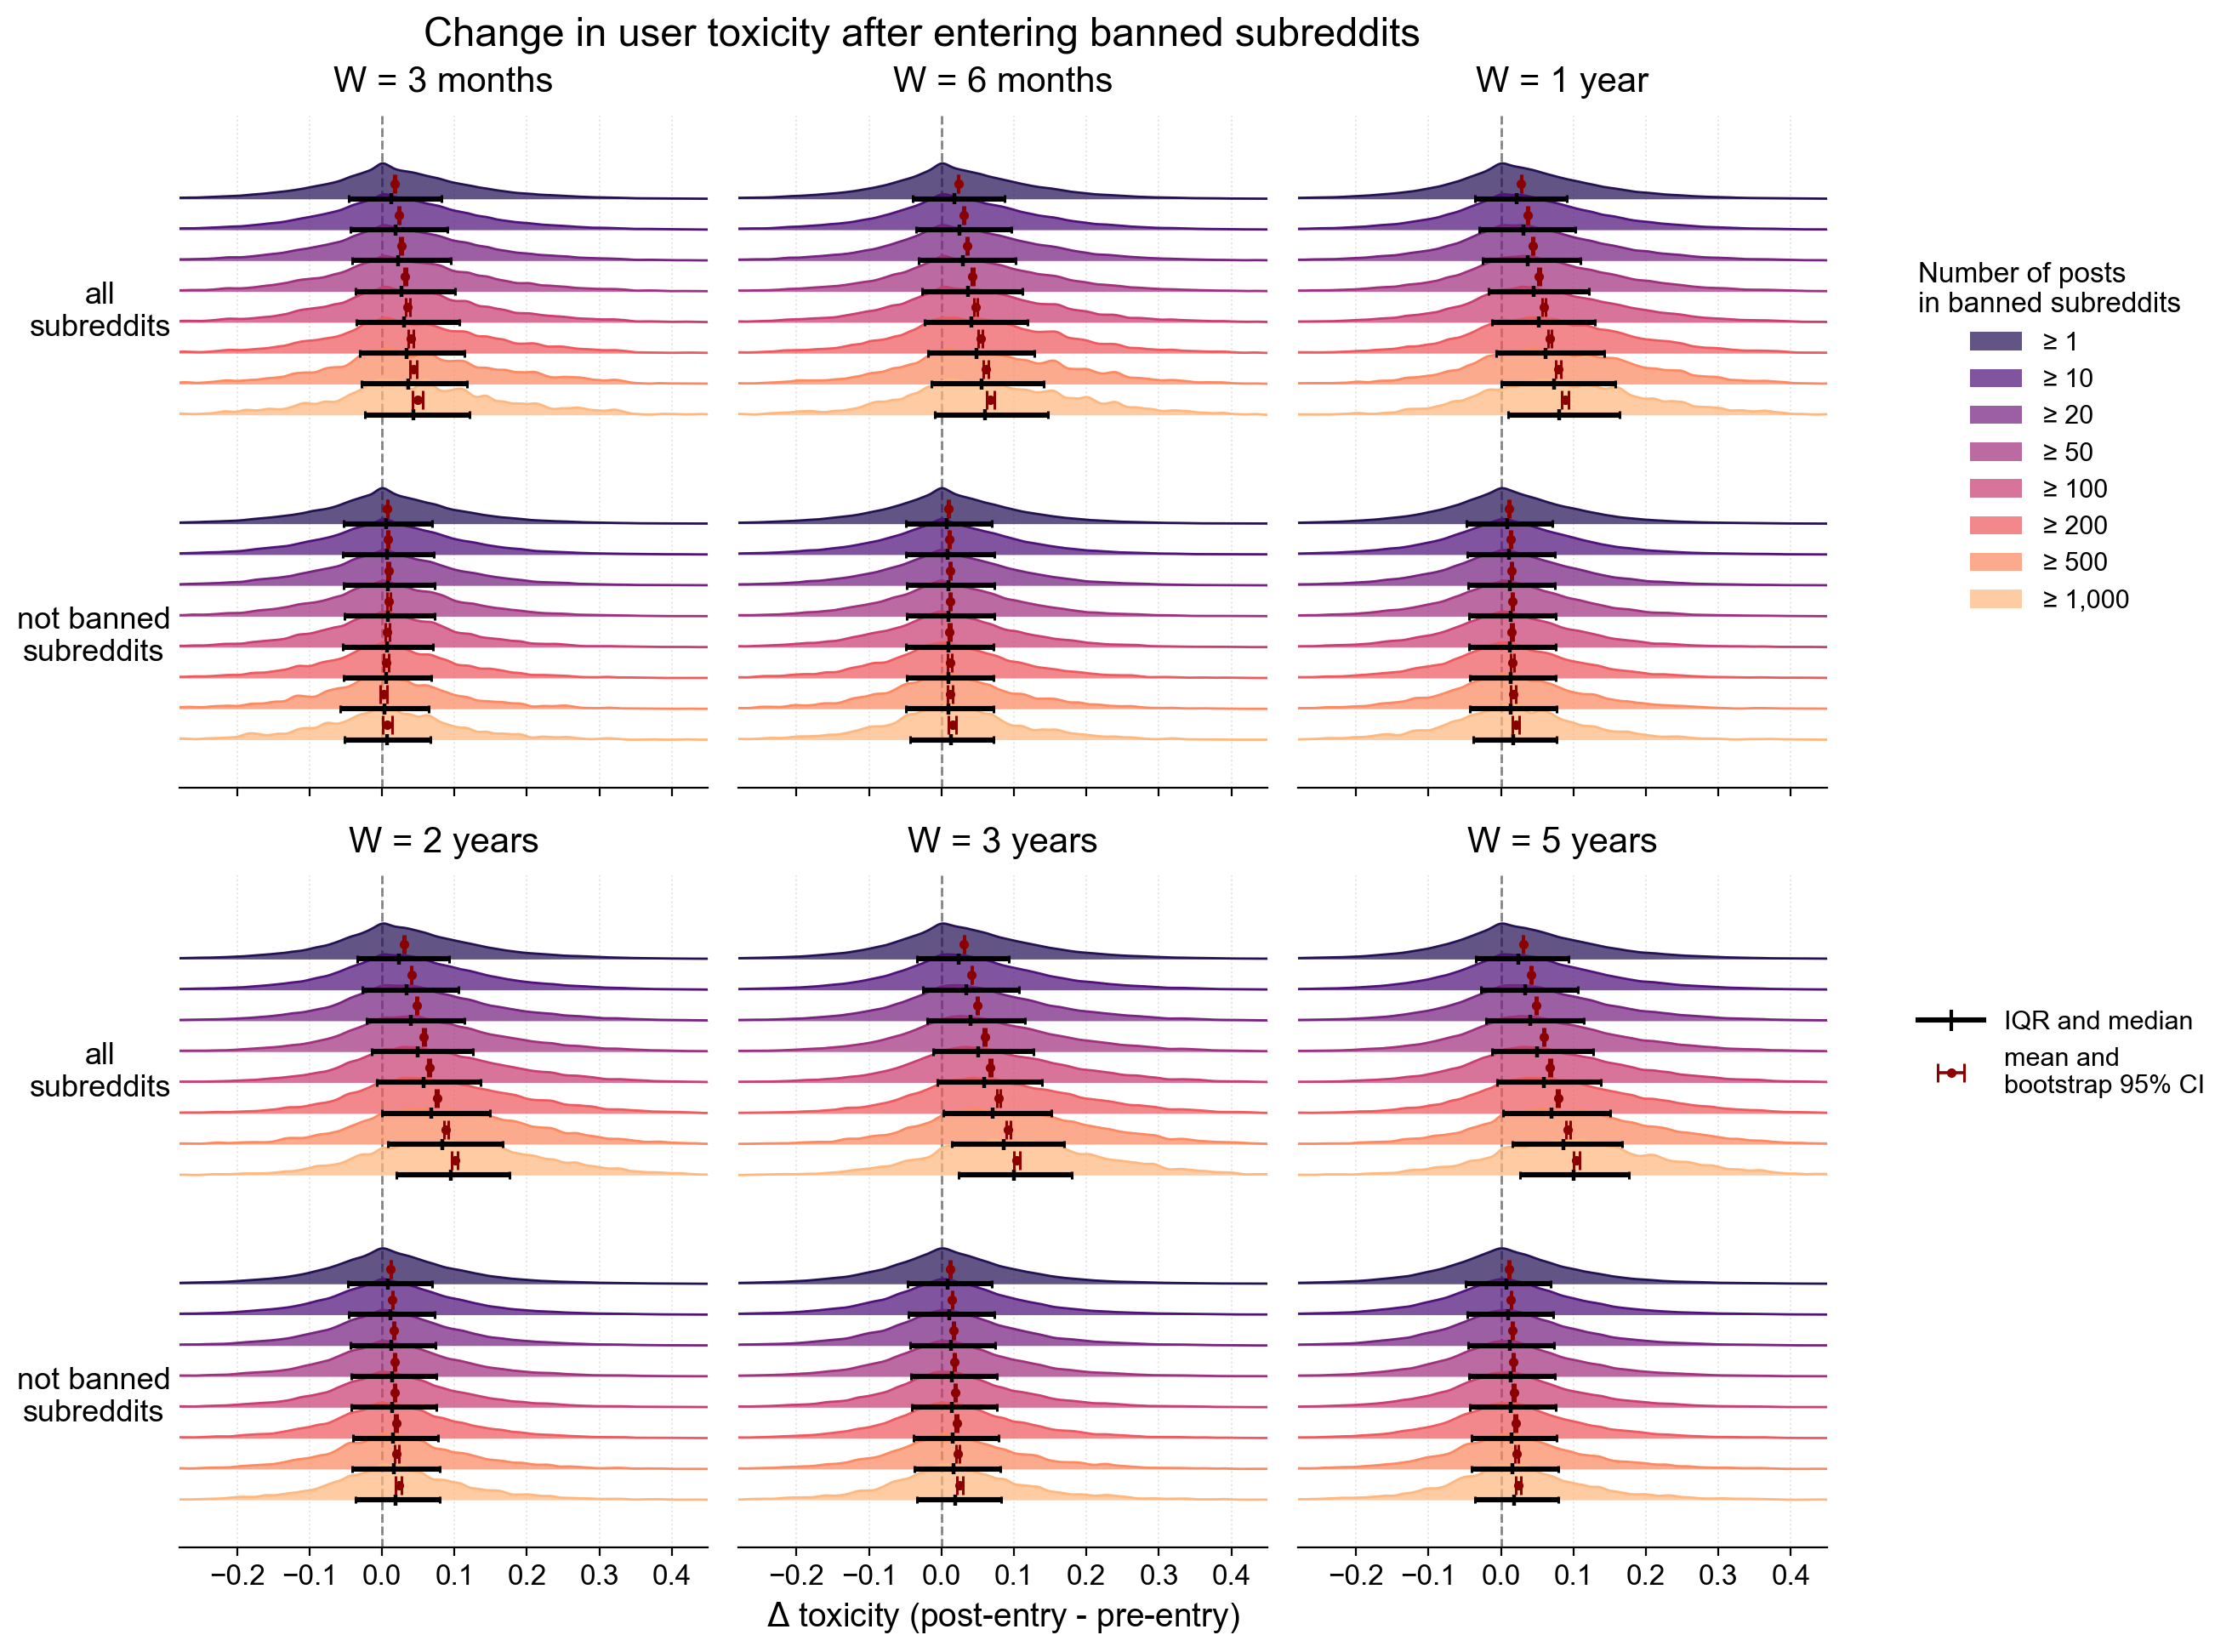

In [23]:
from scipy.ndimage import gaussian_filter1d
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator

ACTIVITY_THRESHOLDS = sorted(ACTIVITY_THRESHOLDS)
outcome_order = ["all", "outside"]

group_centers = np.arange(len(outcome_order), dtype=float)

n_thresholds = len(ACTIVITY_THRESHOLDS)
group_height = 0.76
position_step = group_height / n_thresholds

offsets = (np.arange(n_thresholds) - (n_thresholds - 1) / 2) * position_step
colors = plt.cm.magma(np.linspace(0.15, 0.85, n_thresholds))

# estimate each density across the full possible range of changes in toxicity
density_min, density_max = -1, 1

# display a narrower and substantively relevant range
display_x_min, display_x_max = -0.28, 0.45

N_BINS = 800
SMOOTHING_SIGMA = 3
RIDGE_HEIGHT = position_step * 1.15

bin_edges = np.linspace(density_min, density_max, N_BINS + 1)

x_grid = (bin_edges[:-1] + bin_edges[1:]) / 2


# create faceted figure
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(11,10), sharex=True, sharey=True)
axes = axes.ravel()
plot_axes = axes[:len(WINDOW_SPECS)]

# The sixth subplot is unused.
# axes[-1].axis("off")

for panel_idx, ((window_days, window_label), ax) in enumerate(zip(WINDOW_SPECS, plot_axes)):
    print("processing for:", panel_idx)

    panel_df = user_prepost_window_robustness.filter(pl.col("window_days") == window_days)
    for threshold_idx, threshold in enumerate(ACTIVITY_THRESHOLDS):

        positions = group_centers + offsets[threshold_idx]
        color = colors[threshold_idx]

        for outcome_idx, outcome in enumerate(outcome_order):

            values = (
                panel_df.filter(
                    (pl.col("outcome") == outcome)
                    & (pl.col("inside_activity_threshold") == threshold)
                )
                .get_column("toxicity_change").drop_nulls().to_numpy()
            )

            if len(values) == 0:
                continue

            y_position = positions[outcome_idx]
            density, _ = np.histogram(values, bins=bin_edges, density=True)
            density = gaussian_filter1d(density.astype(float), sigma=SMOOTHING_SIGMA)

            # normalize each density independently.
            # Ridge height therefore does not represent
            # the number of users.
            if density.max() > 0:
                density = density / density.max()

            ridge_top = y_position - RIDGE_HEIGHT * density

            ax.fill_between(
                x_grid, y_position,
                ridge_top,
                color=color,
                alpha=0.72,
                linewidth=0,
                zorder=2,
            )

            ax.plot(
                x_grid, ridge_top,
                color=color,
                linewidth=1.0,
                zorder=3,
            )

            # distribution summaries
            n = len(values)
            mean = np.mean(values)
            q1, median, q3 = np.quantile(values, [0.25, 0.50, 0.75])
            iqr_y = y_position
            mean_ci_y = y_position - RIDGE_HEIGHT * 0.42

            # IQR
            ax.hlines(
                y=iqr_y,
                xmin=q1,
                xmax=q3,
                color="black",
                linewidth=2.2,
                zorder=6,
            )

            # IQR end caps
            iqr_cap_height = position_step * 0.12

            ax.vlines(
                [q1, q3],
                ymin=iqr_y - iqr_cap_height,
                ymax=iqr_y + iqr_cap_height,
                color="black",
                linewidth=1.1,
                zorder=6,
            )

            # median
            ax.vlines(
                median,
                ymin=iqr_y - position_step * 0.18,
                ymax=iqr_y + position_step * 0.18,
                color="black",
                linewidth=1.6,
                zorder=7,
            )

            # mean and bootstrap 95% CI
            if n > 1:

                ci_low, ci_high = bootstrap_mean_ci(values, n_bootstraps=N_BOOTSTRAPS)

                ax.errorbar(
                    x=mean,
                    y=mean_ci_y,
                    xerr=np.array([[mean - ci_low], [ci_high - mean]]),
                    fmt=".",
                    color="darkred",
                    ecolor="darkred",
                    markersize=6,
                    elinewidth=1.3,
                    capsize=4,
                    capthick=1.1,
                    zorder=9,
                )

    ax.axvline(0, color="grey", linestyle="--", linewidth=1, zorder=1)
    ax.set_title(f"W = {window_label}", fontsize=15, pad=10)
    ax.set_xlim(display_x_min, display_x_max)
    ax.xaxis.set_major_locator(MultipleLocator(0.1))
    ax.grid(axis="x", linestyle=":", linewidth=0.7, alpha=0.35, zorder=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0,)

    # display outcome labels only in the left column.
    if panel_idx % 3 == 0:
        ax.set_yticks(group_centers)
        ax.set_yticklabels(["all\nsubreddits", "not banned\nsubreddits"], fontsize=13)
        for label in ax.get_yticklabels():
            label.set_multialignment("center")
        ax.tick_params(axis="y", labelleft=True)
    else:
        ax.tick_params(axis="y", labelleft=False)

    # reversed limits produce the same ridge orientation
    # as in the original figure.
    ax.set_ylim(
        group_centers[-1] + group_height / 2 + 0.10,
        group_centers[0] - group_height / 2 - RIDGE_HEIGHT - 0.10,
    )
    if panel_idx == 4:
        ax.set_xlabel(r"$\Delta$ toxicity (post-entry - pre-entry)", fontsize=14)

fig.suptitle("Change in user toxicity after entering banned subreddits", fontsize=17, y=0.97)
# fig.supxlabel(r"$\Delta$ toxicity (post-entry - pre-entry)", fontsize=14, y=0.035)

threshold_legend_handles = [
    Patch(facecolor=colors[idx], edgecolor="none", alpha=0.72, label=f"≥ {threshold:,}")
    for idx, threshold in enumerate(ACTIVITY_THRESHOLDS)
]

threshold_legend = fig.legend(
    handles=threshold_legend_handles,
    title="Number of posts\nin banned subreddits",
    frameon=False,
    bbox_to_anchor=(1.02, 0.84),
    loc="upper left",
    fontsize=11,
    title_fontsize=12,
)

iqr_handle = Line2D(
    [0], [0],
    color="black",
    linewidth=2.2,
    marker="|",
    markersize=9,
    markeredgewidth=1.5,
    label="IQR and median",
)

mean_ci_handle = axes[-1].errorbar(
    [np.nan], [np.nan],
    xerr=[0.1],
    fmt=".",
    color="darkred",
    ecolor="darkred",
    markersize=6,
    elinewidth=1.3,
    capsize=4,
    capthick=1.1,
    label="mean and\nbootstrap 95% CI",
)

summary_legend = fig.legend(
    handles=[iqr_handle, mean_ci_handle],
    frameon=False,
    bbox_to_anchor=(1.02, 0.40),
    loc="upper left",
    fontsize=11,
    handlelength=2.5,
)

fig.subplots_adjust(
    left=0.11,
    right=0.80,
    top=0.91,
    bottom=0.08,
    hspace=0.35,
    wspace=0.10,
)
plt.tight_layout()
# plt.savefig( "../../output/appendix/toxicity_change_ridge_varying_window_length.png", dpi=300, bbox_inches="tight")
# plt.savefig( "../../output/appendix/toxicity_change_ridge_varying_window_length.pdf", dpi=300, bbox_inches="tight")

## thresholding using within-banned lifespan [skipped]

In [20]:
LIFESPAN_THRESHOLDS = [1, 180, 360, 720, 1080, 1440, 1800]
WINDOW_DAYS = 365
MIN_SUBMISSIONS_EACH_PERIOD = 10
INSIDE_ACTIVITY_THRESHOLD = 10
outcome_order = ["all", "outside"]

threshold_results2 = []

for threshold in LIFESPAN_THRESHOLDS:
    print("Processing inside activity threshold:", threshold)
    for outcome in outcome_order:
        result = get_user_prepost_df(
            context_df=context_df,
            outcome=outcome,
            window_days=WINDOW_DAYS,
            min_submissions_per_period=MIN_SUBMISSIONS_EACH_PERIOD,
            inside_activity_threshold=INSIDE_ACTIVITY_THRESHOLD,
            inside_lifespan_threshold=threshold,
        )

        result = result.with_columns([
            pl.lit(outcome).alias("outcome"),
            pl.lit(threshold).alias("inside_lifespan_threshold"),
        ])

        threshold_results2.append(result)


user_prepost_thresholds2 = (
    pl.concat(
        threshold_results2,
        how="vertical_relaxed",
    )
    .drop_nulls("toxicity_change")
)

user_prepost_thresholds2

Processing inside activity threshold: 1
Processing inside activity threshold: 180
Processing inside activity threshold: 360
Processing inside activity threshold: 720
Processing inside activity threshold: 1080
Processing inside activity threshold: 1440
Processing inside activity threshold: 1800


author,pre_toxicity,n_pre_submissions,post_toxicity,n_post_submissions,n_posts,first_post_date,last_post_date,active_days,toxicity_change,outcome,inside_lifespan_threshold
str,f64,u32,f64,u32,u32,datetime[ms],datetime[ms],i64,f64,str,i32
"""CxDub1""",0.073642,14,0.161456,12,43,2016-03-01 14:52:13,2016-06-12 19:45:56,104,0.087813,"""all""",1
"""Comeck""",0.625392,25,0.483401,327,27,2016-02-26 14:21:45,2019-07-27 08:54:51,1247,-0.141991,"""all""",1
"""HornyAltAccount""",0.478868,13,0.96343,19,19,2018-03-08 17:55:10,2019-01-06 14:30:33,304,0.484563,"""all""",1
"""JoeDrunk""",0.211781,45,0.178154,41,12,2018-03-19 05:28:40,2019-07-02 22:32:04,471,-0.033627,"""all""",1
"""Senior_Z""",0.262522,10,0.209888,19,53,2016-07-07 12:47:50,2018-09-16 00:21:41,801,-0.052634,"""all""",1
…,…,…,…,…,…,…,…,…,…,…,…
"""Kolchakk""",0.145719,19,0.096806,16,31,2014-09-20 03:02:19,2019-12-26 14:27:20,1924,-0.048912,"""outside""",1800
"""Parkwaydrivehighway""",0.354088,38,0.282356,155,288,2013-12-29 20:04:22,2019-12-25 09:54:40,2187,-0.071732,"""outside""",1800
"""Jracx""",0.107277,45,0.044099,60,11,2013-11-05 07:04:06,2019-04-24 19:00:57,1997,-0.063178,"""outside""",1800


In [21]:
# check sample sizes
threshold_sample_sizes2 = (
    user_prepost_thresholds2
    .group_by(["inside_lifespan_threshold", "outcome"])
    .agg([
        pl.len().alias("n_users"),
        pl.col("toxicity_change").mean().alias("mean_change"),
        pl.col("toxicity_change").median().alias("median_change"),
    ])
    .sort(["inside_lifespan_threshold", "outcome"])
)

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(threshold_sample_sizes2.filter(pl.col("outcome") == "all"))
    print(threshold_sample_sizes2.filter(pl.col("outcome") == "outside"))

shape: (7, 5)
┌───────────────────────────┬─────────┬─────────┬─────────────┬───────────────┐
│ inside_lifespan_threshold ┆ outcome ┆ n_users ┆ mean_change ┆ median_change │
│ ---                       ┆ ---     ┆ ---     ┆ ---         ┆ ---           │
│ i32                       ┆ str     ┆ u32     ┆ f64         ┆ f64           │
╞═══════════════════════════╪═════════╪═════════╪═════════════╪═══════════════╡
│ 1                         ┆ all     ┆ 55663   ┆ 0.036469    ┆ 0.030571      │
│ 180                       ┆ all     ┆ 41695   ┆ 0.037698    ┆ 0.031684      │
│ 360                       ┆ all     ┆ 29634   ┆ 0.036445    ┆ 0.030469      │
│ 720                       ┆ all     ┆ 16778   ┆ 0.032334    ┆ 0.027297      │
│ 1080                      ┆ all     ┆ 8987    ┆ 0.031977    ┆ 0.025623      │
│ 1440                      ┆ all     ┆ 2023    ┆ 0.005064    ┆ 0.003435      │
│ 1800                      ┆ all     ┆ 1033    ┆ -0.006284   ┆ -0.005452     │
└─────────────────────────

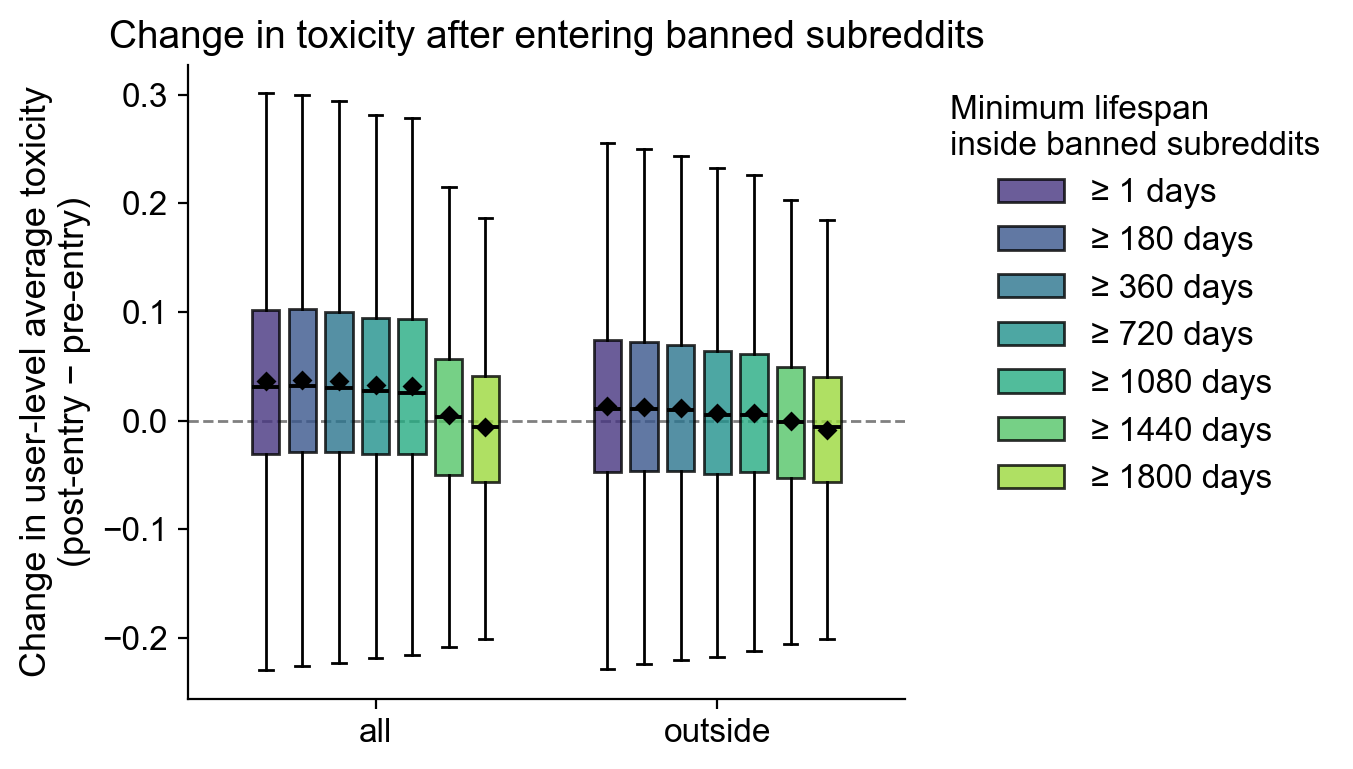

In [22]:
from matplotlib.patches import Patch

LIFESPAN_THRESHOLDS = sorted(LIFESPAN_THRESHOLDS)
outcome_order = ["all", "outside"]


group_centers = np.arange(len(outcome_order))
n_thresholds = len(LIFESPAN_THRESHOLDS)
group_width = 0.75
position_step = group_width / n_thresholds
box_width = position_step * 0.75
offsets = (np.arange(n_thresholds) - (n_thresholds - 1) / 2) * position_step
colors = plt.cm.viridis(np.linspace(0.15, 0.85, n_thresholds))


fig, ax = plt.subplots(figsize=(7,4))
legend_handles = []
for threshold_idx, threshold in enumerate(LIFESPAN_THRESHOLDS):

    threshold_boxplot_data = []

    for outcome in outcome_order:
        values = (
            user_prepost_thresholds2
            .filter(
                (pl.col("outcome") == outcome)
                & (
                    pl.col("inside_lifespan_threshold")
                    == threshold
                )
            )
            .get_column("toxicity_change")
            .drop_nulls()
            .to_numpy()
        )

        threshold_boxplot_data.append(values)

    # One position inside each outcome group
    positions = group_centers + offsets[threshold_idx]

    bp = ax.boxplot(
        threshold_boxplot_data,
        positions=positions,
        widths=box_width,
        patch_artist=True,
        showfliers=False,
        showmeans=True,
        whis=1.5,
        meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black", "markersize": 4},
        medianprops={"color": "black", "linewidth": 1.4},
        boxprops={"edgecolor": "black", "linewidth": 1.0},
        whiskerprops={"color": "black", "linewidth": 1.0},
        capprops={"color": "black", "linewidth": 1.0},
    )

    # Apply the threshold-specific color
    for box in bp["boxes"]:
        box.set_facecolor(colors[threshold_idx])
        box.set_alpha(0.8)

    legend_handles.append(
        Patch(
            facecolor=colors[threshold_idx],
            edgecolor="black",
            alpha=0.8,
            label=f"≥ {threshold} days",
        )
    )


# No-change reference line
ax.axhline(
    0,
    color="grey",
    linestyle="--",
    linewidth=1,
    zorder=0,
)

ax.set_xticks(group_centers)
ax.set_xticklabels(["all", "outside"], fontsize=12)
ax.set_ylabel("Change in user-level average toxicity\n(post-entry − pre-entry)", fontsize=13)
ax.set_title("Change in toxicity after entering banned subreddits", fontsize=14)

ax.legend(
    handles=legend_handles,
    title="Minimum lifespan\ninside banned subreddits",
    frameon=False,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

ax.spines[["top", "right"]].set_visible(False)

# Give the leftmost and rightmost boxes sufficient space
ax.set_xlim(
    group_centers[0] - 0.55,
    group_centers[-1] + 0.55,
)

plt.tight_layout()
plt.show()